# 03 · Modelo de previsión de rendimiento

Objetivo: estimar los minutos visualizados durante los 7 primeros días de un vídeo largo a partir de lo
ocurrido en sus 2 primeros días, y dar un rango de valores razonables en lugar de una cifra única.

Planteamiento:
- **Día 1** = día de publicación en el calendario de Analytics (ver `01_preprocesamiento`).
- **Objetivo**: `minutos_7d`, modelado en escala logarítmica por su gran dispersión.
- **Entradas**: los minutos de cada uno de los 2 primeros días y las horas del día 1 que quedan desde la
  publicación hasta la medianoche del Pacífico. Se comparan además otras variables (minutos por visualización,
  suscriptores netos, duración y día de la semana), y el modelo final conserva solo las tres primeras.
  2 días, duración, hora (Madrid) y día de la semana.
- **Variables excluidas**: totales por vídeo, retención, fuentes de tráfico, ingresos y cualquier cifra posterior
  al día 2, porque se acumulan durante toda la vida del vídeo y filtrarían el futuro al modelo.
- **Validación**: partición temporal (los vídeos más antiguos entrenan, los más recientes evalúan).
- **Referencia**: escalar los minutos de los primeros días con el peso histórico mediano de esos días.
  El modelo solo aporta si mejora esta referencia, sobre todo en los minutos que llegan después de los días observados.

## 1. Configuración

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

RUTA_PROCESADOS = Path("../data/processed")
HORIZONTE_OBJETIVO = 7          # días de la ventana que se quiere predecir
DIAS_ENTRADA = 2                # días de observación que alimentan el modelo
DIAS_COMPARADOS = (1, 2, 3)     # ventanas iniciales que se contrastan con la referencia ingenua
FRACCION_ENTRENAMIENTO = 0.75   # los vídeos más antiguos entrenan; los recientes evalúan
FECHA_INICIO_MODELO = pd.Timestamp("2025-01-01", tz="UTC")  # el canal tiene 2 vídeos de 2017 y ninguno hasta 2025
SEMILLA = 42

COLUMNAS_NECESARIAS = [
    "video_id", "title", "published_at", "formato", "largo_breve", "duration_seconds",
    "hora_madrid", "dia_semana", "dias_observados", "periodo_7d",
    "minutos_1d", "minutos_2d", "minutos_3d", "minutos_7d",
    f"vistas_{DIAS_ENTRADA}d", f"subs_netos_{DIAS_ENTRADA}d",
]

## 2. Carga y comprobación de columnas

In [2]:
maestra = pd.read_csv(RUTA_PROCESADOS / "videos_maestra.csv")
maestra["published_at"] = pd.to_datetime(maestra["published_at"], utc=True)
panel = pd.read_csv(RUTA_PROCESADOS / "panel_diario.csv")

faltan = [c for c in COLUMNAS_NECESARIAS if c not in maestra.columns]
print("Filas maestra:", len(maestra), "| filas panel:", len(panel))
print("Columnas que faltan:", faltan if faltan else "ninguna")
print("Tipo de dia_semana:", maestra["dia_semana"].dtype)

Filas maestra: 352 | filas panel: 128489
Columnas que faltan: ninguna
Tipo de dia_semana: int64


## 3. Población de modelado

Se modelan los vídeos largos con la ventana de 7 días completa y publicados desde 2025. Los dos vídeos de 2017
quedan fuera: son casos aislados, ocho años anteriores al resto, y el modelo no puede aprender de ellos.

In [3]:
largos = maestra[maestra["formato"] == "long"].copy()
completos = largos[largos["minutos_7d"].notna()].copy()
anteriores = completos["published_at"] < FECHA_INICIO_MODELO
completos = completos[~anteriores].sort_values("published_at").reset_index(drop=True)

print(f"Vídeos largos: {len(largos)}")
print(f"Con ventana de 7 días completa: {len(largos) - int(largos['minutos_7d'].isna().sum())}")
print(f"Excluidos por ser anteriores a {FECHA_INICIO_MODELO.date()}: {int(anteriores.sum())}")
print(f"Vídeos de modelado: {len(completos)}")
print(f"De ellos con marca largo_breve: {int(completos['largo_breve'].sum())}")
print("Rango de publicación:", completos["published_at"].min().date(), "→",
      completos["published_at"].max().date())
print("Vídeos con minutos_7d = 0:", int((completos["minutos_7d"] == 0).sum()))
print("Vídeos con minutos_1d = 0:", int((completos["minutos_1d"] == 0).sum()))

Vídeos largos: 260
Con ventana de 7 días completa: 255
Excluidos por ser anteriores a 2025-01-01: 2
Vídeos de modelado: 253
De ellos con marca largo_breve: 7
Rango de publicación: 2025-02-12 → 2026-10-12
Vídeos con minutos_7d = 0: 0
Vídeos con minutos_1d = 0: 0


## 4. Variables de entrada

Los minutos de cada día salen del panel diario; el resto, de la tabla maestra. Se comprueba que ninguna variable
contenga información posterior al último día de entrada.

In [4]:
d = completos.set_index("video_id")
diarios = (
    panel[panel["dia_rel"] < DIAS_ENTRADA]
    .pivot_table(index="video_id", columns="dia_rel", values="estimatedMinutesWatched", aggfunc="sum")
)
diarios.columns = [f"min_dia{int(c) + 1}" for c in diarios.columns]

X = pd.DataFrame(index=d.index)
X = X.join(diarios)
X[f"vistas_{DIAS_ENTRADA}d"] = d[f"vistas_{DIAS_ENTRADA}d"]
X[f"subs_netos_{DIAS_ENTRADA}d"] = d[f"subs_netos_{DIAS_ENTRADA}d"]
X["duracion_min"] = d["duration_seconds"] / 60
X["hora_madrid"] = d["hora_madrid"]
X["dia_semana"] = d["dia_semana"]
y = d["minutos_7d"]

PROHIBIDAS = ("total", "retencion", "fuente", "ingresos", "rpm", "28d", "7d")
solapadas = [c for c in X.columns if any(p in c for p in PROHIBIDAS)]
solapadas += [c for c in X.columns if c.startswith("min_dia") and int(c[-1]) > DIAS_ENTRADA]
print("Variables de entrada:", list(X.columns))
print("Variables con nombre sospechoso de fuga:", solapadas if solapadas else "ninguna")
print("Nulos por variable:\n" + X.isna().sum().to_string())

# coherencia: suma de los días de entrada del panel frente a la columna acumulada de la maestra
columnas_dias = [f"min_dia{i}" for i in range(1, DIAS_ENTRADA + 1)]
dif = (X[columnas_dias].sum(axis=1) - d[f"minutos_{DIAS_ENTRADA}d"]).abs()
print(f"\nDiferencia máxima panel vs minutos_{DIAS_ENTRADA}d: {dif.max():.4f} min")

Variables de entrada: ['min_dia1', 'min_dia2', 'vistas_2d', 'subs_netos_2d', 'duracion_min', 'hora_madrid', 'dia_semana']
Variables con nombre sospechoso de fuga: ninguna
Nulos por variable:
min_dia1         0
min_dia2         0
vistas_2d        0
subs_netos_2d    0
duracion_min     0
hora_madrid      0
dia_semana       0

Diferencia máxima panel vs minutos_2d: 0.0000 min


## 5. Peso de los primeros días sobre los 7 días

Qué parte de los minutos de la semana ocurre en los primeros días. Su dispersión marca cuánto margen tiene un modelo
frente a la referencia de escalar con un peso fijo.

In [5]:
pesos_vistos = pd.DataFrame(
    {f"{n} d": d[f"minutos_{n}d"] / d["minutos_7d"] for n in DIAS_COMPARADOS}
)
print(pesos_vistos.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(3).to_string())

           1 d      2 d      3 d
count  253.000  253.000  253.000
mean     0.456    0.722    0.837
std      0.178    0.170    0.144
min      0.002    0.130    0.241
10%      0.181    0.469    0.651
25%      0.351    0.632    0.752
50%      0.475    0.765    0.871
75%      0.567    0.843    0.944
90%      0.669    0.905    0.989
max      0.846    0.994    0.998


## 6. Partición temporal

Los vídeos se ordenan por fecha de publicación. El 75 % más antiguo entrena y el 25 % más reciente evalúa, de modo
que el modelo nunca se evalúa con vídeos anteriores a los de entrenamiento. El conjunto de prueba incluye vídeos
posteriores al cambio de criterio de visualizaciones del 24/08/2026.

In [6]:
corte = int(len(completos) * FRACCION_ENTRENAMIENTO)
id_train, id_test = completos["video_id"][:corte], completos["video_id"][corte:]
X_train, X_test = X.loc[id_train], X.loc[id_test]
y_train, y_test = y.loc[id_train], y.loc[id_test]

print(f"Entrenamiento: {len(X_train)} vídeos ({completos['published_at'][:corte].min().date()} → "
      f"{completos['published_at'][corte - 1].date()})")
print(f"Prueba: {len(X_test)} vídeos ({completos['published_at'][corte].date()} → "
      f"{completos['published_at'].max().date()})")
print("Periodo de medición (periodo_7d) en entrenamiento:",
      completos.loc[:corte - 1, "periodo_7d"].value_counts().to_dict())
print("Periodo de medición (periodo_7d) en prueba:",
      completos.loc[corte:, "periodo_7d"].value_counts().to_dict())
print("\nMinutos a 7 días (mediana / p90 / máx):")
for nombre, serie in (("train", y_train), ("test", y_test)):
    print(f"  {nombre}: {serie.median():,.0f} / {serie.quantile(.9):,.0f} / {serie.max():,.0f}")

Entrenamiento: 189 vídeos (2025-02-12 → 2026-04-14)
Prueba: 64 vídeos (2026-04-17 → 2026-10-12)
Periodo de medición (periodo_7d) en entrenamiento: {'previo': 189}
Periodo de medición (periodo_7d) en prueba: {'previo': 36, 'posterior': 25, 'mixto': 3}

Minutos a 7 días (mediana / p90 / máx):
  train: 11,781 / 56,843 / 538,726
  test: 28,057 / 90,536 / 247,719


## 7. Referencias ingenuas

Referencia: multiplicar los minutos observados en los primeros días por la inversa de su peso mediano histórico
(calculado solo con los vídeos de entrenamiento). Se mide el error en escala logarítmica sobre el total a 7 días y
sobre el resto, es decir, los minutos que llegan después de los días observados. El modelo tendrá que mejorar,
sobre todo, esa segunda cifra.

In [7]:
def error_log(real, pred):
    return np.log1p(real) - np.log1p(pred)


def resumen(nombre, real, pred, observado):
    """Métricas sobre el total a 7 días y sobre la parte aún no observada."""
    e = error_log(real, pred)
    r2 = 1 - (e ** 2).sum() / ((np.log1p(real) - np.log1p(real).mean()) ** 2).sum()
    resto_real = (real - observado).clip(lower=0)
    resto_pred = (pred - observado).clip(lower=0)
    e_resto = error_log(resto_real, resto_pred)
    return {
        "referencia": nombre,
        "MAE_log_7d": np.abs(e).mean(),
        "R2_log_7d": r2,
        "MAE_log_resto": np.abs(e_resto).mean(),
        "error_rel_mediano_7d": (np.abs(real - pred) / real.replace(0, np.nan)).median(),
    }


pesos = {n: (d.loc[id_train, f"minutos_{n}d"] / y_train).median() for n in DIAS_COMPARADOS}
print("Peso mediano del tramo inicial sobre los 7 días (train):",
      ", ".join(f"{n} d = {p:.3f}" for n, p in pesos.items()))

filas = []
for n, peso in pesos.items():
    observado = d.loc[id_test, f"minutos_{n}d"]
    filas.append(resumen(f"escala con {n} d", y_test, observado / peso, observado))
observado = d.loc[id_test, f"minutos_{DIAS_ENTRADA}d"]
mediana = pd.Series(y_train.median(), index=y_test.index)
filas.append(resumen("mediana histórica", y_test, mediana, observado))
print(pd.DataFrame(filas).round(3).to_string(index=False))

Peso mediano del tramo inicial sobre los 7 días (train): 1 d = 0.464, 2 d = 0.757, 3 d = 0.861
       referencia  MAE_log_7d  R2_log_7d  MAE_log_resto  error_rel_mediano_7d
   escala con 1 d       0.336      0.763          0.671                 0.308
   escala con 2 d       0.184      0.913          0.780                 0.129
   escala con 3 d       0.117      0.960          0.935                 0.082
mediana histórica       1.107     -0.708          6.744                 0.699


## 8. Planteamiento de los modelos

En lugar de predecir los minutos a 7 días directamente, se predice cuánto crecen respecto a los 2 primeros días:
`log(1 + minutos_7d) - log(1 + minutos_2d)`. Con esta formulación la referencia ingenua es un valor constante
(el crecimiento mediano), y cualquier modelo parte de ella y solo aprende la corrección. La predicción en minutos se
reconstruye a partir de lo ya observado.

Se comparan dos familias, con una versión base y otra ampliada de variables:
- **Regresión Ridge** (lineal con penalización), interpretable, con tres niveles de regularización.
- **Gradient boosting** con árboles poco profundos, capaz de captar relaciones no lineales.

Variables base: tamaño de los 2 primeros días, cociente entre el día 2 y el día 1 (velocidad) y horas del día 1 que
quedan desde la publicación hasta la medianoche del Pacífico. Esta última corrige que el día 1 es un día natural: un vídeo
subido por la tarde en California apenas aporta horas de observación a ese día. Variables ampliadas: además, minutos por
visualización, suscriptores netos por mil visualizaciones, duración y día de la semana.

In [8]:
import sys

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Las funciones que construyen las variables viven en src/modelo.py, para que cuaderno y aplicación usen el mismo código
sys.path.insert(0, str(Path("..").resolve()))
from src.modelo import construir_variables

F = construir_variables(X, d["published_at"])
print(F.describe().round(2).to_string())
print("\nNulos o infinitos:", int(F.isna().sum().sum() + np.isinf(F.to_numpy(dtype=float)).sum()))

       log_min_2d  log_cociente_d2_d1  horas_dia1  log_min_por_vista  asinh_subs_por_mil  log_duracion_min  dia_semana
count      253.00              253.00      253.00             253.00              253.00            253.00      253.00
mean         8.78               -0.51       16.73               1.52                1.94              2.51        2.59
std          2.02                0.86        3.74               0.71                1.24              0.77        1.83
min          2.30               -2.91        0.38              -0.94               -1.47              0.56        0.00
25%          8.12               -0.94       14.98               1.08                1.00              2.09        1.00
50%          9.34               -0.53       16.00               1.60                2.03              2.41        2.00
75%         10.11               -0.20       19.92               2.01                2.87              2.81        4.00
max         12.53                5.63       24.0

## 9. Candidatos y objetivo

Se define el objetivo (crecimiento en logaritmo) y la lista de modelos candidatos. La referencia ingenua es un modelo
constante: predice siempre el crecimiento mediano de los vídeos de entrenamiento.

In [9]:
y_crecimiento = np.log1p(y) - np.log1p(d[f"minutos_{DIAS_ENTRADA}d"])
observado_total = d[f"minutos_{DIAS_ENTRADA}d"]

VARIABLES_BASE = ["log_min_2d", "log_cociente_d2_d1", "horas_dia1"]
VARIABLES_AMPLIADAS = VARIABLES_BASE + [
    "log_min_por_vista", "asinh_subs_por_mil", "log_duracion_min", "dia_semana",
]
REFERENCIA = "referencia: crecimiento mediano"


def ridge(alpha, columnas):
    numericas = [c for c in columnas if c != "dia_semana"]
    bloques = [("num", StandardScaler(), numericas)]
    if "dia_semana" in columnas:
        bloques.append(("dia", OneHotEncoder(handle_unknown="ignore"), ["dia_semana"]))
    return Pipeline([("prep", ColumnTransformer(bloques)), ("modelo", Ridge(alpha=alpha))])


def arboles():
    return GradientBoostingRegressor(
        loss="huber", n_estimators=150, learning_rate=0.03, max_depth=2,
        subsample=0.8, random_state=SEMILLA,
    )


candidatos = {REFERENCIA: (VARIABLES_BASE, lambda: DummyRegressor(strategy="median"))}
for alpha in (1, 10, 100):
    candidatos[f"ridge base (alpha={alpha})"] = (VARIABLES_BASE, lambda a=alpha: ridge(a, VARIABLES_BASE))
    candidatos[f"ridge ampliada (alpha={alpha})"] = (VARIABLES_AMPLIADAS, lambda a=alpha: ridge(a, VARIABLES_AMPLIADAS))
candidatos["árboles base"] = (VARIABLES_BASE, arboles)
candidatos["árboles ampliada"] = (VARIABLES_AMPLIADAS, arboles)

print(f"Candidatos: {len(candidatos)}")
for nombre, (columnas, _) in candidatos.items():
    print(f"  {nombre:36s} {len(columnas)} variables")

Candidatos: 9
  referencia: crecimiento mediano      3 variables
  ridge base (alpha=1)                 3 variables
  ridge ampliada (alpha=1)             7 variables
  ridge base (alpha=10)                3 variables
  ridge ampliada (alpha=10)            7 variables
  ridge base (alpha=100)               3 variables
  ridge ampliada (alpha=100)           7 variables
  árboles base                         3 variables
  árboles ampliada                     7 variables


## 10. Validación cruzada temporal

Solo con los vídeos de entrenamiento. Cada pliegue entrena con los vídeos más antiguos y valida con los siguientes,
dejando un hueco de 3 vídeos entre ambos (la ventana de 7 días de un vídeo se solapa con la publicación de los
siguientes). Así el modelo nunca se valida con datos anteriores a los que ha visto. El conjunto de prueba no se
usa en este bloque.

In [10]:
cv = TimeSeriesSplit(n_splits=5, gap=3)
orden = list(id_train)
F_ent, r_ent = F.loc[orden], y_crecimiento.loc[orden]
obs_ent, y_ent = observado_total.loc[orden], y.loc[orden]

resultados = {nombre: [] for nombre in candidatos}
for k, (idx_ent, idx_val) in enumerate(cv.split(F_ent), start=1):
    fechas = completos.set_index("video_id").loc[F_ent.index[idx_val], "published_at"]
    print(f"Pliegue {k}: entrena con {len(idx_ent)} vídeos, valida con {len(idx_val)} "
          f"({fechas.min().date()} → {fechas.max().date()})")
    for nombre, (columnas, fabrica) in candidatos.items():
        modelo = fabrica()
        modelo.fit(F_ent.iloc[idx_ent][columnas], r_ent.iloc[idx_ent])
        crecimiento = modelo.predict(F_ent.iloc[idx_val][columnas])
        obs = obs_ent.iloc[idx_val]
        prediccion = np.expm1(np.log1p(obs) + crecimiento)
        metricas = resumen(nombre, y_ent.iloc[idx_val], prediccion, obs)
        metricas["pliegue"] = k
        resultados[nombre].append(metricas)

referencia_pliegues = pd.DataFrame(resultados[REFERENCIA]).set_index("pliegue")["MAE_log_7d"]
filas = []
for nombre, lista in resultados.items():
    por_pliegue = pd.DataFrame(lista).set_index("pliegue")
    filas.append({
        "modelo": nombre,
        "MAE_log_7d": por_pliegue["MAE_log_7d"].mean(),
        "desv": por_pliegue["MAE_log_7d"].std(),
        "MAE_log_resto": por_pliegue["MAE_log_resto"].mean(),
        "error_rel_mediano": por_pliegue["error_rel_mediano_7d"].mean(),
        "pliegues_mejor_que_ref": int((por_pliegue["MAE_log_7d"] < referencia_pliegues).sum()),
    })
tabla_cv = pd.DataFrame(filas).sort_values("MAE_log_7d").reset_index(drop=True)
print()
print(tabla_cv.round(3).to_string(index=False))

Pliegue 1: entrena con 31 vídeos, valida con 31 (2025-04-01 → 2025-05-16)
Pliegue 2: entrena con 62 vídeos, valida con 31 (2025-05-19 → 2025-08-23)
Pliegue 3: entrena con 93 vídeos, valida con 31 (2025-08-24 → 2025-11-03)
Pliegue 4: entrena con 124 vídeos, valida con 31 (2025-11-04 → 2025-12-22)
Pliegue 5: entrena con 155 vídeos, valida con 31 (2025-12-23 → 2026-04-14)

                         modelo  MAE_log_7d  desv  MAE_log_resto  error_rel_mediano  pliegues_mejor_que_ref
                   árboles base       0.190 0.061          0.743              0.165                       5
               árboles ampliada       0.193 0.069          0.744              0.169                       4
      ridge ampliada (alpha=10)       0.201 0.063          0.762              0.176                       3
       ridge ampliada (alpha=1)       0.201 0.069          0.772              0.177                       2
           ridge base (alpha=1)       0.203 0.066          0.767              0.182    

## 11. Elección del modelo

Se elige el candidato con menor error medio en la validación cruzada. Si ninguno mejora de forma clara a la
referencia ingenua, se conserva la referencia.

In [11]:
mejor = tabla_cv.iloc[0]
ref = tabla_cv[tabla_cv["modelo"] == REFERENCIA].iloc[0]
mejora = 1 - mejor["MAE_log_7d"] / ref["MAE_log_7d"]
mejora_resto = 1 - mejor["MAE_log_resto"] / ref["MAE_log_resto"]
print(f"Mejor candidato: {mejor['modelo']}")
print(f"Reducción del error medio sobre el total a 7 días: {mejora:.1%}")
print(f"Reducción del error medio sobre el resto no observado: {mejora_resto:.1%}")
print(f"Pliegues en que mejora a la referencia: {int(mejor['pliegues_mejor_que_ref'])} de {cv.n_splits}")
MODELO_ELEGIDO = mejor["modelo"]

Mejor candidato: árboles base
Reducción del error medio sobre el total a 7 días: 10.9%
Reducción del error medio sobre el resto no observado: 8.4%
Pliegues en que mejora a la referencia: 5 de 5


## 12. Evaluación en el conjunto de prueba

Se reajusta el modelo elegido y la referencia con todo el entrenamiento y se evalúan una sola vez con los vídeos más
recientes. Como la prueba tiene pocos vídeos, la mejora se acompaña de un intervalo por remuestreo para ver cuánto
puede variar.

In [12]:
def ajustar(columnas, fabrica, ids_entrenamiento):
    """Entrena un candidato con los vídeos indicados."""
    modelo = fabrica()
    modelo.fit(F.loc[ids_entrenamiento, columnas], y_crecimiento.loc[ids_entrenamiento])
    return modelo


def predecir_minutos(modelo, columnas, ids):
    """Devuelve los minutos a 7 días previstos y el crecimiento en logaritmo que los origina."""
    crecimiento = modelo.predict(F.loc[ids, columnas])
    observado = observado_total.loc[ids]
    return np.expm1(np.log1p(observado) + crecimiento), crecimiento


columnas_elegidas, fabrica_elegida = candidatos[MODELO_ELEGIDO]
columnas_ref, fabrica_ref = candidatos[REFERENCIA]

modelo_prueba = ajustar(columnas_elegidas, fabrica_elegida, id_train)
referencia_prueba = ajustar(columnas_ref, fabrica_ref, id_train)

obs_test = observado_total.loc[id_test]
pred_modelo, crecimiento_modelo = predecir_minutos(modelo_prueba, columnas_elegidas, id_test)
pred_ref, crecimiento_ref = predecir_minutos(referencia_prueba, columnas_ref, id_test)

tabla_prueba = pd.DataFrame(
    [
        resumen(REFERENCIA, y_test, pred_ref, obs_test),
        resumen(MODELO_ELEGIDO, y_test, pred_modelo, obs_test),
    ]
)
print("Evaluación en el conjunto de prueba (se consulta una sola vez):")
print(tabla_prueba.round(3).to_string(index=False))

# Incertidumbre de la mejora: remuestreo de los vídeos de prueba
err_modelo = np.abs(error_log(y_test, pred_modelo)).to_numpy()
err_ref = np.abs(error_log(y_test, pred_ref)).to_numpy()
rng = np.random.default_rng(SEMILLA)
reducciones = []
for _ in range(2000):
    muestra = rng.integers(0, len(err_modelo), len(err_modelo))
    reducciones.append(1 - err_modelo[muestra].mean() / err_ref[muestra].mean())
inferior_red, superior_red = np.percentile(reducciones, [5, 95])
print(f"\nReducción del error absoluto medio frente a la referencia: {1 - err_modelo.mean() / err_ref.mean():.1%}")
print(f"Intervalo al 90 % por remuestreo: {inferior_red:.1%} a {superior_red:.1%}")
print(f"Vídeos de prueba en que el modelo se equivoca menos que la referencia: "
      f"{int((err_modelo < err_ref).sum())} de {len(err_ref)}")

Evaluación en el conjunto de prueba (se consulta una sola vez):
                     referencia  MAE_log_7d  R2_log_7d  MAE_log_resto  error_rel_mediano_7d
referencia: crecimiento mediano       0.184      0.913          0.779                 0.128
                   árboles base       0.156      0.944          0.673                 0.106

Reducción del error absoluto medio frente a la referencia: 15.2%
Intervalo al 90 % por remuestreo: 8.8% a 20.3%
Vídeos de prueba en que el modelo se equivoca menos que la referencia: 43 de 64


## 13. Rango de predicción

Una cifra única transmite una precisión que el modelo no tiene. Se calcula un intervalo del 80 % con los errores que el
modelo comete en la validación temporal (vídeos que no ha visto al entrenar) y se comprueba en la prueba qué
proporción de vídeos cae dentro. Los minutos acumulados no pueden ser menores que los ya observados, así que el
límite inferior se recorta a ese valor.

In [13]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))
from src.modelo import intervalo_minutos

def predicciones_fuera_de_muestra(columnas, fabrica, ids):
    """Crecimiento previsto para cada vídeo por un modelo que no lo ha visto (validación temporal)."""
    ids = list(ids)
    previsto = {}
    for idx_ent, idx_val in TimeSeriesSplit(n_splits=5, gap=3).split(np.arange(len(ids))):
        ids_ent = [ids[i] for i in idx_ent]
        ids_val = [ids[i] for i in idx_val]
        modelo = ajustar(columnas, fabrica, ids_ent)
        previsto.update(zip(ids_val, modelo.predict(F.loc[ids_val, columnas])))
    return pd.Series(previsto)


def calibrar_intervalo(columnas, fabrica, ids, nivel=0.80):
    """Cuantiles del error de crecimiento en validación temporal, para un intervalo del nivel indicado."""
    previsto = predicciones_fuera_de_muestra(columnas, fabrica, ids)
    residuos = y_crecimiento.loc[previsto.index] - previsto
    cola = (1 - nivel) / 2
    return residuos.quantile(cola), residuos.quantile(1 - cola)


filas = []
for nombre, columnas, fabrica, crecimiento in (
    (REFERENCIA, columnas_ref, fabrica_ref, crecimiento_ref),
    (MODELO_ELEGIDO, columnas_elegidas, fabrica_elegida, crecimiento_modelo),
):
    q_inf, q_sup = calibrar_intervalo(columnas, fabrica, id_train)
    inferior, superior = intervalo_minutos(obs_test, crecimiento, q_inf, q_sup)
    dentro = (y_test >= inferior) & (y_test <= superior)
    filas.append(
        {
            "modelo": nombre,
            "cuantil_10": q_inf,
            "cuantil_90": q_sup,
            "cobertura_prueba": dentro.mean(),
            "por_debajo": (y_test < inferior).mean(),
            "por_encima": (y_test > superior).mean(),
            "anchura_mediana (sup/inf)": (superior / inferior).median(),
        }
    )
print("Intervalos al 80 % calibrados con el entrenamiento y comprobados en la prueba:")
print(pd.DataFrame(filas).round(3).to_string(index=False))

Intervalos al 80 % calibrados con el entrenamiento y comprobados en la prueba:
                         modelo  cuantil_10  cuantil_90  cobertura_prueba  por_debajo  por_encima  anchura_mediana (sup/inf)
referencia: crecimiento mediano      -0.351        0.23             0.828         0.0       0.172                      1.661
                   árboles base      -0.286        0.27             0.875         0.0       0.125                      1.701


## 14. Pruebas de sensibilidad

Se repite la evaluación quitando lo que podría estar condicionando el resultado: el vídeo de mayor tamaño (un caso
extremo del entrenamiento), los largos de duración breve, y separando los vídeos de prueba según si su ventana
queda antes o después del cambio de criterio de visualizaciones del 24/08/2026. Si la mejora se mantiene en todas las
variantes, no depende de un caso concreto.

In [14]:
periodo = completos.set_index("video_id")["periodo_7d"]
breves = set(completos.loc[completos["largo_breve"], "video_id"])
video_mayor = y.loc[id_train].idxmax()


def evaluar_variante(nombre, ids_ent, ids_prueba):
    modelo = ajustar(columnas_elegidas, fabrica_elegida, ids_ent)
    ref = ajustar(columnas_ref, fabrica_ref, ids_ent)
    observado = observado_total.loc[ids_prueba]
    real = y.loc[ids_prueba]
    p_mod, _ = predecir_minutos(modelo, columnas_elegidas, ids_prueba)
    p_ref, _ = predecir_minutos(ref, columnas_ref, ids_prueba)

    def error_resto(prediccion):
        return np.abs(
            error_log((real - observado).clip(lower=0), (prediccion - observado).clip(lower=0))
        ).mean()

    mae_modelo = np.abs(error_log(real, p_mod)).mean()
    mae_ref = np.abs(error_log(real, p_ref)).mean()
    return {
        "variante": nombre,
        "vídeos_prueba": len(ids_prueba),
        "MAE_modelo": mae_modelo,
        "MAE_referencia": mae_ref,
        "reducción": 1 - mae_modelo / mae_ref,
        "reducción_resto": 1 - error_resto(p_mod) / error_resto(p_ref),
    }


lista_train, lista_test = list(id_train), list(id_test)
variantes = [
    evaluar_variante("completa", lista_train, lista_test),
    evaluar_variante(
        f"sin el vídeo de mayor tamaño ({y.loc[video_mayor]:,.0f} min)",
        [v for v in lista_train if v != video_mayor],
        lista_test,
    ),
    evaluar_variante(
        "sin los largos breves",
        [v for v in lista_train if v not in breves],
        [v for v in lista_test if v not in breves],
    ),
    evaluar_variante(
        "prueba solo con ventana anterior al 24/08",
        lista_train,
        [v for v in lista_test if periodo[v] == "previo"],
    ),
    evaluar_variante(
        "prueba solo con ventana posterior o mixta",
        lista_train,
        [v for v in lista_test if periodo[v] != "previo"],
    ),
]
print(pd.DataFrame(variantes).round(3).to_string(index=False))

                                  variante  vídeos_prueba  MAE_modelo  MAE_referencia  reducción  reducción_resto
                                  completa             64       0.156           0.184      0.152            0.136
sin el vídeo de mayor tamaño (538,726 min)             64       0.153           0.184      0.169            0.156
                     sin los largos breves             63       0.151           0.180      0.160            0.146
 prueba solo con ventana anterior al 24/08             36       0.135           0.162      0.166            0.161
 prueba solo con ventana posterior o mixta             28       0.183           0.212      0.138            0.119


## 15. Importancia de las variables

Importancia por permutación en la prueba: se desordena una variable cada vez y se mide cuánto empeora el error. Cuanto
mayor es el aumento, más depende el modelo de esa variable. Una importancia próxima a cero significa que la variable no
aporta con estos datos.

Aumento del error medio (log) al desordenar cada variable en la prueba:
          variable  aumento_del_error  desviacion
log_cociente_d2_d1             0.0312      0.0058
        horas_dia1             0.0051      0.0023
        log_min_2d             0.0020      0.0021


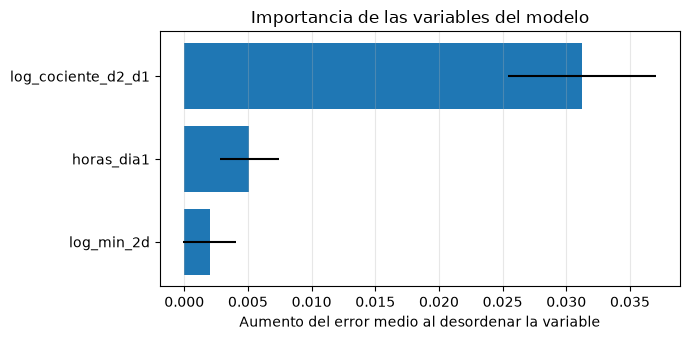

In [15]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

importancia = permutation_importance(
    modelo_prueba,
    F.loc[id_test, columnas_elegidas],
    y_crecimiento.loc[id_test],
    scoring="neg_mean_absolute_error",
    n_repeats=30,
    random_state=SEMILLA,
)
tabla_importancia = (
    pd.DataFrame(
        {
            "variable": columnas_elegidas,
            "aumento_del_error": importancia.importances_mean,
            "desviacion": importancia.importances_std,
        }
    )
    .sort_values("aumento_del_error", ascending=False)
    .reset_index(drop=True)
)
print("Aumento del error medio (log) al desordenar cada variable en la prueba:")
print(tabla_importancia.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
orden_grafico = tabla_importancia.iloc[::-1]
ax.barh(orden_grafico["variable"], orden_grafico["aumento_del_error"], xerr=orden_grafico["desviacion"])
ax.set_xlabel("Aumento del error medio al desordenar la variable")
ax.set_title("Importancia de las variables del modelo")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## 16. Modelo final y guardado

El modelo que usará la aplicación se reajusta con todos los vídeos disponibles, entrenamiento y prueba, para aprovechar
también los más recientes. El intervalo del 80 % se vuelve a calibrar con la validación temporal sobre todos ellos. El
paquete guardado incluye el modelo, sus variables, el intervalo y las versiones de las librerías con las que se creó.

In [16]:
q_inf_total, q_sup_total = calibrar_intervalo(columnas_elegidas, fabrica_elegida, list(completos["video_id"]))
print(f"Cuantiles del error de crecimiento (80 %): {q_inf_total:.3f} y {q_sup_total:.3f}")
print(f"Multiplicador del intervalo sobre la estimación central: "
      f"{np.exp(q_inf_total):.2f}x a {np.exp(q_sup_total):.2f}x")

Cuantiles del error de crecimiento (80 %): -0.235 y 0.300
Multiplicador del intervalo sobre la estimación central: 0.79x a 1.35x


In [17]:
import sys

from joblib import dump
import sklearn

CARPETA_MODELOS = Path("../models")
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

ids_todos = list(completos["video_id"])
modelo_final = ajustar(columnas_elegidas, fabrica_elegida, ids_todos)
referencia_final = ajustar(columnas_ref, fabrica_ref, ids_todos)

paquete = {
    "nombre_modelo": MODELO_ELEGIDO,
    "modelo": modelo_final,
    "columnas": columnas_elegidas,
    "dias_entrada": DIAS_ENTRADA,
    "horizonte": HORIZONTE_OBJETIVO,
    "cuantil_inferior": float(q_inf_total),
    "cuantil_superior": float(q_sup_total),
    "nivel_intervalo": 0.80,
    "crecimiento_mediano": float(referencia_final.predict(F.loc[ids_todos[:1], columnas_ref])[0]),
    "videos_entrenamiento": len(ids_todos),
    "primera_publicacion": str(completos["published_at"].min().date()),
    "ultima_publicacion": str(completos["published_at"].max().date()),
    "versiones": {
        "python": sys.version.split()[0],
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}
dump(paquete, CARPETA_MODELOS / "modelo_prevision_2d.joblib")
print(f"Modelo guardado: {CARPETA_MODELOS / 'modelo_prevision_2d.joblib'}")
print(f"Entrenado con {len(ids_todos)} vídeos publicados entre {paquete['primera_publicacion']} y {paquete['ultima_publicacion']}")
print("Versiones:", paquete["versiones"])

Modelo guardado: ..\models\modelo_prevision_2d.joblib
Entrenado con 253 vídeos publicados entre 2025-02-12 y 2026-10-12
Versiones: {'python': '3.14.3', 'scikit-learn': '1.9.1', 'pandas': '3.1.0', 'numpy': '2.5.4'}


## 17. Conclusión del modelo

**Qué se ha construido.** Un modelo que estima los minutos visualizados a 7 días de un vídeo largo a partir de sus 2 primeros días, con un rango de valores razonables. Se entrena con 253 vídeos largos publicados entre el 12/02/2025 y el 12/10/2026 (189 para entrenar y 64, los más recientes, para evaluar). Predice el crecimiento respecto a los 2 primeros días y usa tres variables: el cociente de minutos entre el día 2 y el día 1 (velocidad), las horas del día 1 que quedan desde la publicación hasta la medianoche del Pacífico, y los minutos de los 2 días. El modelo es de gradient boosting con árboles poco profundos, elegido por validación cruzada temporal frente a regresiones Ridge y a la referencia.

**Cuánto mejora la referencia.** La referencia es la regla simple de multiplicar los minutos de los 2 primeros días por el crecimiento mediano histórico, que ya es una buena predicción porque a los 2 días se conoce en mediana el 76 % del resultado. Sobre los 64 vídeos de prueba:

| | Referencia | Modelo |
|---|---|---|
| Error medio en logaritmo (7 días) | 0,184 | 0,156 |
| Error relativo mediano | 12,8 % | 10,6 % |
| R² en logaritmo | 0,913 | 0,944 |
| Error en los minutos que llegan después de los 2 días | 0,779 | 0,673 |

La reducción del error es del 15,2 % (intervalo al 90 % por remuestreo: 8,8 % a 20,3 %), y el modelo se equivoca menos que la referencia en 43 de 64 vídeos. La mejora se mantiene entre el 13,8 % y el 16,9 % al quitar el vídeo de 538.726 minutos, al quitar los largos breves y al separar los vídeos con ventana anterior o posterior al cambio de criterio del 24/08/2026. Es una mejora real pero moderada: la mayor parte de la información ya está en los minutos de los 2 primeros días.

**Qué aporta la predicción.** La variable que más pesa es la velocidad del vídeo (cuánto crece el día 2 respecto al día 1), como anticipaba el análisis exploratorio. Las horas del día 1 corrigen una cuestión de medida: el día 1 es un día natural del Pacífico y un vídeo subido por la tarde apenas aporta horas de observación a ese día. No indican que publicar a cierta hora haga crecer más un vídeo, conclusión que el análisis exploratorio tampoco encontraba. Los minutos por visualización, los suscriptores netos, la duración y el día de la semana no mejoran la validación y quedan fuera del modelo final.

**Rango de predicción.** El intervalo del 80 % equivale a multiplicar la estimación central por 0,79 y 1,35 en el modelo final, sin bajar nunca de los minutos ya observados. Para comprobarlo se calibró primero solo con el entrenamiento (factores de 0,75 y 1,31) y se evaluó en la prueba: contiene el valor real en el 87,5 % de los vídeos, ninguno queda por debajo y el 12,5 % queda por encima. El límite inferior suele coincidir con los minutos ya observados, así que el rango informa sobre todo por arriba, y se queda algo corto en los vídeos que se disparan, que son los que más interesan.

**Limitaciones.**
- Hacen falta los 2 primeros días de datos del vídeo, incluida su fecha y hora de publicación. No sirve para decidir antes de publicar.
- La prueba tiene 64 vídeos, de modo que las cifras tienen una incertidumbre apreciable, como muestra el intervalo de la mejora.
- Tras el cambio de criterio del 24/08/2026 el error absoluto es mayor tanto en el modelo como en la referencia, y se desconoce si las visualizaciones del propio día 1 usan ya el criterio nuevo. Los minutos, que son el objetivo, no dependen de él.
- El modelo se ha entrenado con un solo canal y no incluye el contenido del vídeo, las impresiones ni el CTR, que no están en los datos descargados.
- El canal creció mucho en 2025 y 2026, y el modelo no se ha probado con vídeos mucho mayores que los vistos.
- El día 1 es parcial y su duración depende de la hora de subida; las horas restantes del día 1 se calculan en hora del Pacífico, la que usa la API para agrupar los días.